# 📊 Gold Spot
Notebook 01: Preprocessing

## Preliminaries

In [1]:
import pandas as pd
from src.extract import fetch_fred, fetch_prices
from src.preprocessing_functions import *
from src.config import clean_data_file, daily_cols, monthly_cols

### Extract macro data

In [2]:
df_macro = fetch_fred()
df_macro.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 4441 entries, 2010-01-01 to 2026-10-21
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   real_yield_10y         4202 non-null   float64
 1   dxy_broad_goods        4181 non-null   float64
 2   vix_index              4259 non-null   float64
 3   industrial_production  201 non-null    float64
 4   unemployment_rate      200 non-null    float64
 5   cpi_headline           200 non-null    float64
dtypes: float64(6)
memory usage: 242.9 KB


In [3]:
# Se remuestran a fin de mes aplicando lag de 1 periodo a series macro mensuales
df_macro_monthly = process_macro_to_monthly(df_raw=df_macro, daily_columns=daily_cols, monthly_columns=monthly_cols)
df_macro_monthly.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 201 entries, 2010-01-31 to 2026-09-30
Data columns (total 6 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   real_yield_10y              201 non-null    float64
 1   dxy_broad_goods             201 non-null    float64
 2   vix_index                   201 non-null    float64
 3   industrial_production_lag1  200 non-null    float64
 4   unemployment_rate_lag1      199 non-null    float64
 5   cpi_headline_lag1           199 non-null    float64
dtypes: float64(6)
memory usage: 11.0 KB


In [4]:
# Mostrar missings iniciales
show_missings(df_macro_monthly)

unemployment_rate_lag1        0.009950
cpi_headline_lag1             0.009950
industrial_production_lag1    0.004975
dtype: float64

In [5]:
# Ver datos faltantes
print(df_macro_monthly[df_macro_monthly["cpi_headline_lag1"].isna()])

            real_yield_10y  dxy_broad_goods  vix_index  \
date                                                     
2010-01-31            1.30          93.7638      24.62   
2025-11-30            1.79         121.0527      16.35   

            industrial_production_lag1  unemployment_rate_lag1  \
date                                                             
2010-01-31                         NaN                     NaN   
2025-11-30                    101.2195                     NaN   

            cpi_headline_lag1  
date                           
2010-01-31                NaN  
2025-11-30                NaN  


In [6]:
# Se aplica forward fill y se mantienen missings iniciales
df_macro_monthly = df_macro_monthly.ffill(limit=1)
show_missings(df_macro_monthly)

industrial_production_lag1    0.004975
unemployment_rate_lag1        0.004975
cpi_headline_lag1             0.004975
dtype: float64

### Extract prices

In [7]:
df_prices = fetch_prices()

# Se elimina la fila del mes en curso
df_historical_prices = drop_incomplete_month(df_prices)

df_historical_prices.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 201 entries, 2010-01-31 to 2026-09-30
Freq: ME
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   oil     201 non-null    float64
 1   gold    201 non-null    float64
 2   spy     201 non-null    float64
dtypes: float64(3)
memory usage: 6.3 KB


### Merge datasets

In [8]:
df_merged = df_macro_monthly.join(df_historical_prices, how="inner")
df_merged.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 201 entries, 2010-01-31 to 2026-09-30
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   real_yield_10y              201 non-null    float64
 1   dxy_broad_goods             201 non-null    float64
 2   vix_index                   201 non-null    float64
 3   industrial_production_lag1  200 non-null    float64
 4   unemployment_rate_lag1      200 non-null    float64
 5   cpi_headline_lag1           200 non-null    float64
 6   oil                         201 non-null    float64
 7   gold                        201 non-null    float64
 8   spy                         201 non-null    float64
dtypes: float64(9)
memory usage: 15.7 KB


## Feature Engineering

In [9]:
# Variaciones porcentuales mensuales
monthly_return_cols = [
    'oil',
    'gold',
    'spy',
    'dxy_broad_goods',
    'vix_index',
]
df_features = calculate_return(df_merged, cols=monthly_return_cols, periods=1)

# Variaciones porcentuales YoY
yearly_return_cols = [
    'oil',
    'gold',
    'spy',
    'cpi_headline_lag1',
    'industrial_production_lag1'
]
df_features = calculate_return(df_features, cols=yearly_return_cols, periods=12)

# Cambios absolutos en variables originales porcentuales mensuales
monthly_yield_cols = [
    'real_yield_10y'
]
df_features = calculate_delta(df_features, cols=monthly_yield_cols, periods=1)

# Cambios absolutos YoY
yearly_yield_cols = [
    'unemployment_rate_lag1'
]
df_features = calculate_delta(df_features, cols=yearly_yield_cols, periods=12)

# Cambios absolutos QoQ: se aplica sobre la misma columna que el anual
df_features = calculate_delta(df_features, cols=yearly_yield_cols, periods=3)

# Se eliminan columnas base originales no estacionarias
base_cols_to_drop = [
    "oil",
    "gold",
    "spy",
    "dxy_broad_goods",
    "cpi_headline_lag1",
    "industrial_production_lag1",
    "unemployment_rate_lag1",
]
df_features = df_features.drop(columns=base_cols_to_drop)

df_features.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 201 entries, 2010-01-31 to 2026-09-30
Data columns (total 15 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   real_yield_10y                      201 non-null    float64
 1   vix_index                           201 non-null    float64
 2   oil_ret_1m                          200 non-null    float64
 3   gold_ret_1m                         200 non-null    float64
 4   spy_ret_1m                          200 non-null    float64
 5   dxy_broad_goods_ret_1m              200 non-null    float64
 6   vix_index_ret_1m                    200 non-null    float64
 7   oil_ret_12m                         189 non-null    float64
 8   gold_ret_12m                        189 non-null    float64
 9   spy_ret_12m                         189 non-null    float64
 10  cpi_headline_lag1_ret_12m           188 non-null    float64
 11  industrial_production_lag1

In [10]:
# Se eliminan missings iniciales luego del calculo de las diferencias
df_features = df_features.dropna()

## EDA

In [11]:
df_features.describe()

,real_yield_10y,vix_index,oil_ret_1m,gold_ret_1m,spy_ret_1m,dxy_broad_goods_ret_1m,vix_index_ret_1m,oil_ret_12m,gold_ret_12m,spy_ret_12m,cpi_headline_lag1_ret_12m,industrial_production_lag1_ret_12m,real_yield_10y_change_1m,unemployment_rate_lag1_change_12m,unemployment_rate_lag1_change_3m
count,188.000000,188.000000,188.000000,188.000000,188.000000,188.000000,188.000000,188.000000,188.000000,188.000000,188.000000,188.000000,188.000000,188.000000,188.000000
mean,0.560904,18.196383,0.006976,0.007209,0.010349,0.001724,0.027152,0.055635,0.099641,0.129915,0.026795,0.007476,0.009840,-0.338298,-0.085638
std,0.956110,6.419249,0.122351,0.047212,0.041037,0.016296,0.255112,0.388819,0.191847,0.117822,0.019071,0.035451,0.207667,1.943045,1.360739
min,-1.160000,9.510000,-0.542449,-0.121212,-0.129987,-0.037838,-0.458969,-0.705210,-0.282362,-0.194816,-0.002299,-0.173183,-0.510000,-8.700000,-4.800000
25%,-0.007500,13.772500,-0.057092,-0.021294,-0.011585,-0.010062,-0.144775,-0.170452,-0.034175,0.055726,0.015966,-0.008247,-0.110000,-0.900000,-0.300000
50%,0.480000,16.465000,0.008885,0.004777,0.014755,-0.000691,-0.009129,-0.012969,0.069318,0.140006,0.022683,0.012052,-0.020000,-0.500000,-0.100000
75%,1.265000,19.887500,0.061544,0.037497,0.033195,0.013591,0.131685,0.202247,0.225978,0.195025,0.031789,0.027285,0.130000,0.000000,0.000000
max,2.930000,53.540000,0.883758,0.122950,0.126984,0.060224,1.345710,2.374735,0.842338,0.537653,0.089794,0.165521,1.010000,11.100000,11.200000


In [12]:
show_asymmetry(df_features)

unemployment_rate_lag1_change_3m      5.156784
oil_ret_12m                           2.040601
vix_index                             2.014479
oil_ret_1m                            1.812867
unemployment_rate_lag1_change_12m     1.781254
cpi_headline_lag1_ret_12m             1.507277
vix_index_ret_1m                      1.453209
real_yield_10y_change_1m              0.882339
gold_ret_12m                          0.759939
dxy_broad_goods_ret_1m                0.340516
real_yield_10y                        0.234497
spy_ret_12m                          -0.010806
gold_ret_1m                          -0.072571
spy_ret_1m                           -0.325387
industrial_production_lag1_ret_12m   -0.739475


Cont


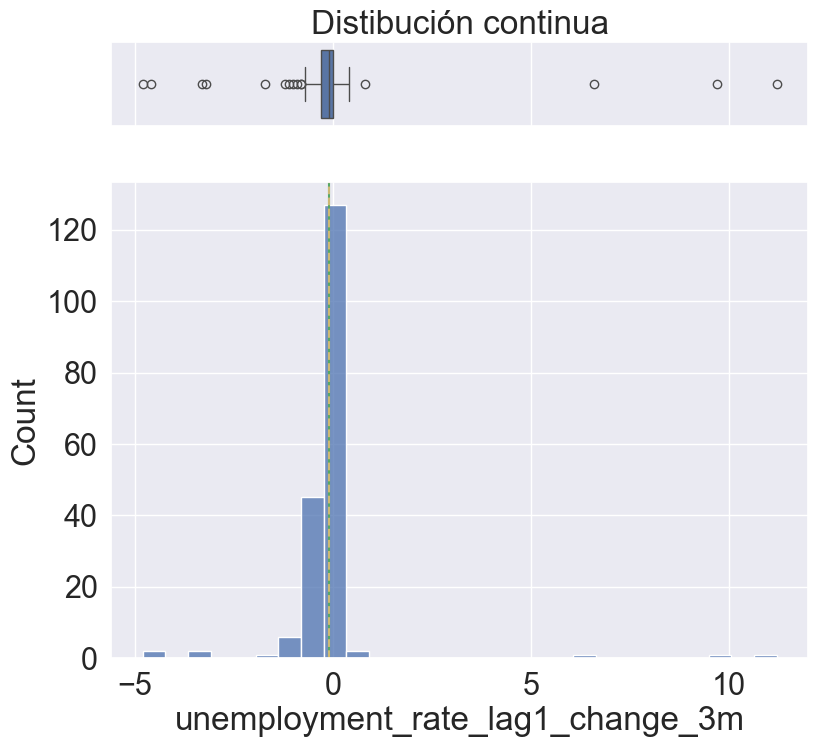

In [14]:
col = 'unemployment_rate_lag1_change_3m'
plot_col(df_features[col])

## Transformations

In [16]:
# Yeo-Johnson 
yeo_cols = ['unemployment_rate_lag1_change_3m']
df_transformed = yeo_transform(df_features, cols=yeo_cols)
show_asymmetry(df_transformed)

oil_ret_12m                             2.040601
vix_index                               2.014479
oil_ret_1m                              1.812867
unemployment_rate_lag1_change_12m       1.781254
cpi_headline_lag1_ret_12m               1.507277
vix_index_ret_1m                        1.453209
real_yield_10y_change_1m                0.882339
gold_ret_12m                            0.759939
dxy_broad_goods_ret_1m                  0.340516
real_yield_10y                          0.234497
spy_ret_12m                            -0.010806
gold_ret_1m                            -0.072571
spy_ret_1m                             -0.325387
industrial_production_lag1_ret_12m     -0.739475
unemployment_rate_lag1_change_3m_Yeo   -1.090552


In [17]:
df_transformed.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 188 entries, 2011-02-28 to 2026-09-30
Data columns (total 15 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   real_yield_10y                        188 non-null    float64
 1   vix_index                             188 non-null    float64
 2   oil_ret_1m                            188 non-null    float64
 3   gold_ret_1m                           188 non-null    float64
 4   spy_ret_1m                            188 non-null    float64
 5   dxy_broad_goods_ret_1m                188 non-null    float64
 6   vix_index_ret_1m                      188 non-null    float64
 7   oil_ret_12m                           188 non-null    float64
 8   gold_ret_12m                          188 non-null    float64
 9   spy_ret_12m                           188 non-null    float64
 10  cpi_headline_lag1_ret_12m             188 non-null    float64
 11  

## Store clean data file

In [18]:
# Asegurar que los directorios existan
clean_data_file.parent.mkdir(parents=True, exist_ok=True)

# Guardar el dataframe
df_transformed.to_parquet(clean_data_file)
print("Clean data file saved.\nContinue to notebook 02_Modeling for the next phase.")


Clean data file saved.
Continue to notebook 02_Modeling for the next phase.
